# Análisis de alumnos matriculados

In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (11, 5)

raw_path = Path("../datos")

archivos = list(raw_path.glob("*.csv"))

len(archivos), archivos


(4,
 [WindowsPath('../datos/Alumnos_matriculados_2015_2019.csv'),
  WindowsPath('../datos/Alumnos_matriculados_2020_2024.csv'),
  WindowsPath('../datos/PDI_2020_2024 (1).csv'),
  WindowsPath('../datos/Presupuesto_gastos_2015_2019.csv')])

In [10]:

df_matricula_1 = pd.read_csv(
    raw_path / "Alumnos_matriculados_2015_2019.csv",
    sep=";",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

df_matricula_2 = pd.read_csv(
    raw_path / "Alumnos_matriculados_2020_2024.csv",
    sep=";",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

df_pdi = pd.read_csv(
    raw_path / "PDI_2020_2024 (1).csv",
    sep=";",
    encoding="utf-8-sig"
)

df_presupuesto = pd.read_csv(
    raw_path / "Presupuesto_gastos_2015_2019.csv",
    sep=";",
    encoding="utf-8-sig"
)

datasets = {
    "Matrícula 2015-2019": df_matricula_1,
    "Matrícula 2020-2024": df_matricula_2,
    "PDI": df_pdi,
    "Presupuesto": df_presupuesto
}

for nombre, df in datasets.items():
    print(f"\n--- {nombre} ---")
    print("Dimensiones:", df.shape)
    print("Columnas:", df.columns.tolist())
    display(df.head())



--- Matrícula 2015-2019 ---
Dimensiones: (558, 5)
Columnas: ['CURSO', 'COD_RUCT', 'TITULACION', 'CENTRO', 'NUMERO_ALUMNOS_MATRICULADOS']


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS
0,2015-16,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,744
1,2015-16,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,202
2,2015-16,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,347
3,2015-16,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,270
4,2015-16,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,338



--- Matrícula 2020-2024 ---
Dimensiones: (615, 5)
Columnas: ['CURSO', 'COD_RUCT', 'TITULACION', 'CENTRO', 'NUMERO_ALUMNOS_MATRICULADOS']


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS
0,2020-21,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,450
1,2020-21,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,224
2,2020-21,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,376
3,2020-21,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,378
4,2020-21,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,356



--- PDI ---
Dimensiones: (2257, 6)
Columnas: ['AÑO', 'COLECTIVO', 'DEPARTAMENTO', 'CATEGORÍA', 'SEXO', 'CASOS']


,AÑO,COLECTIVO,DEPARTAMENTO,CATEGORÍA,SEXO,CASOS
0,2020,PDI,BIOTECNOLOGIA,AYUDANTE,HOMBRE,1
1,2020,PDI,BIOTECNOLOGIA,CATEDRÁTICO DE UNIVERSIDAD,HOMBRE,10
2,2020,PDI,BIOTECNOLOGIA,CATEDRÁTICO DE UNIVERSIDAD,MUJER,5
3,2020,PDI,BIOTECNOLOGIA,PROFESOR ASOCIADO,HOMBRE,3
4,2020,PDI,BIOTECNOLOGIA,PROFESOR ASOCIADO,MUJER,6



--- Presupuesto ---
Dimensiones: (290, 13)
Columnas: ['AÑO', 'CAPITULO', 'DESCRIPCION_CAPITULO', 'CONCEPTO', 'DESCRIPCION_CONCEPTO', 'PRESUPUESTO_INICIAL_EUR', 'MODIFICACIONES_CREDITO_EUR', 'PRESUPUESTO_DEFINITIVO_EUR', 'GASTO_COMPROMETIDO_EUR', 'OBLIGACIONES_RECONOCIDAS_NETAS_EUR', 'REMANENTES_CREDITO_EUR', 'PAGOS_EJERCICIO_CORRIENTE_EUR', 'OBLIGACIONES_PENDIENTES_PAGO_EUR']


,AÑO,CAPITULO,DESCRIPCION_CAPITULO,CONCEPTO,DESCRIPCION_CONCEPTO,PRESUPUESTO_INICIAL_EUR,MODIFICACIONES_CREDITO_EUR,PRESUPUESTO_DEFINITIVO_EUR,GASTO_COMPROMETIDO_EUR,OBLIGACIONES_RECONOCIDAS_NETAS_EUR,REMANENTES_CREDITO_EUR,PAGOS_EJERCICIO_CORRIENTE_EUR,OBLIGACIONES_PENDIENTES_PAGO_EUR
0,2015,1,Gastos de personal,100,Dotación financiera,"0,00","1893291,93","1893291,93","0,00","0,00","1893291,93","0,00","0,00"
1,2015,1,Gastos de personal,110,Dotación Financiera,"153282416,32","-204890,64","153077525,68","0,00","0,00","153077525,68","0,00","0,00"
2,2015,1,Gastos de personal,113,Funcionarios,"0,00","0,00","0,00","132856194,00","132856194,00","-132856194,00","132856194,00","0,00"
3,2015,1,Gastos de personal,114,Laboral fijo,"0,00","0,00","0,00","13501989,01","13501989,01","-13501989,01","13501989,01","0,00"
4,2015,1,Gastos de personal,115,Contrataciones Temporales,"0,00","0,00","0,00","6138764,14","6138764,14","-6138764,14","6138764,14","0,00"


In [11]:

df_matricula = pd.concat(
    [df_matricula_1, df_matricula_2],
    ignore_index=True
)

df_matricula["COD_RUCT"] = (
    df_matricula["COD_RUCT"].astype("string").str.strip()
)

df_matricula["CENTRO"] = (
    df_matricula["CENTRO"].astype("string").str.strip()
)

df_matricula["TITULACION"] = (
    df_matricula["TITULACION"].astype("string").str.strip()
)

df_matricula["NUMERO_ALUMNOS_MATRICULADOS"] = pd.to_numeric(
    df_matricula["NUMERO_ALUMNOS_MATRICULADOS"]
        .astype("string")
        .str.replace(",", ".", regex=False),
    errors="coerce"
)

# Año inicial del curso académico
df_matricula["AÑO_INICIO"] = (
    df_matricula["CURSO"].str[:4].astype(int)
)

df_matricula = df_matricula.sort_values(
    ["AÑO_INICIO", "COD_RUCT", "CENTRO"]
).reset_index(drop=True)

print("Dimensiones:", df_matricula.shape)
display(df_matricula.head())


Dimensiones: (1173, 6)


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS,AÑO_INICIO
0,2015-16,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,744,2015
1,2015-16,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,202,2015
2,2015-16,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,347,2015
3,2015-16,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,270,2015
4,2015-16,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,338,2015


In [12]:

claves_matricula = ["CURSO",'TITULACION', "COD_RUCT", "CENTRO"]

duplicados = df_matricula[
    df_matricula.duplicated(
        subset=claves_matricula,
        keep=False
    )
]

print("Filas con clave repetida:", len(duplicados))
display(duplicados.head(20))

print("\nValores ausentes:")
display(df_matricula.isna().sum())

print("\nEstadísticos:")
display(df_matricula["NUMERO_ALUMNOS_MATRICULADOS"].describe())


Filas con clave repetida: 0


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS,AÑO_INICIO



Valores ausentes:


CURSO                          0
COD_RUCT                       0
TITULACION                     0
CENTRO                         0
NUMERO_ALUMNOS_MATRICULADOS    0
AÑO_INICIO                     0
dtype: int64


Estadísticos:


count        1173.0
mean     221.757886
std      345.399392
min             2.0
25%            37.0
50%            63.0
75%           302.0
max          2133.0
Name: NUMERO_ALUMNOS_MATRICULADOS, dtype: Float64

# Análisis PDI


In [13]:

df_pdi = df_pdi.copy()

df_pdi["AÑO"] = pd.to_numeric(
    df_pdi["AÑO"], errors="coerce"
).astype("Int64")

df_pdi["CASOS"] = pd.to_numeric(
    df_pdi["CASOS"]
        .astype("string")
        .str.replace(",", ".", regex=False),
    errors="coerce"
)

for col in ["DEPARTAMENTO", "CATEGORÍA", "SEXO", "COLECTIVO"]:
    df_pdi[col] = (
        df_pdi[col].astype("string").str.strip()
    )

print("Valores ausentes:")
display(df_pdi.isna().sum())

print("\nEstadísticos del PDI:")
display(df_pdi["CASOS"].describe())

print("\nCategorías:")
display(df_pdi["CATEGORÍA"].value_counts())

print("\nColectivos:")
display(df_pdi["COLECTIVO"].value_counts(dropna=False))


Valores ausentes:


AÑO             0
COLECTIVO       0
DEPARTAMENTO    0
CATEGORÍA       0
SEXO            0
CASOS           0
dtype: int64


Estadísticos del PDI:


count      2257.0
mean     5.695171
std      7.191845
min           1.0
25%           1.0
50%           3.0
75%           7.0
max          53.0
Name: CASOS, dtype: Float64


Categorías:


CATEGORÍA
PROFESOR TITULAR DE UNIVERSIDAD              415
CATEDRÁTICO DE UNIVERSIDAD                   360
PROFESOR ASOCIADO                            347
PROFESOR CONTRATADO DOCTOR                   282
PROFESOR TITULAR DE ESCUELA UNIVERSITARIA    212
AYUDANTE                                     151
PROFESOR/A PERMANENTE LABORAL TITULAR        133
PROFESOR COLABORADOR                         117
PROFESOR AYUDANTE DOCTOR                     100
PROFESOR EMÉRITO                              68
CATEDRÁTICO DE ESCUELA UNIVERSITARIA          66
PROFESOR SUSTITUTO                             4
PROFESOR VISITANTE                             1
PROFESOR/A DISTINGUIDO/A                       1
Name: count, dtype: Int64


Colectivos:


COLECTIVO
PDI    2257
Name: count, dtype: Int64

In [14]:

claves_pdi = [
    "AÑO", "COLECTIVO", "DEPARTAMENTO",
    "CATEGORÍA", "SEXO"
]

duplicados_pdi = df_pdi[
    df_pdi.duplicated(claves_pdi, keep=False)
]

print("Claves repetidas:", len(duplicados_pdi))
display(duplicados_pdi.head(20))


Claves repetidas: 0


,AÑO,COLECTIVO,DEPARTAMENTO,CATEGORÍA,SEXO,CASOS


In [15]:

df_presupuesto = df_presupuesto.copy()

columnas_economicas = [
    "PRESUPUESTO_INICIAL_EUR",
    "MODIFICACIONES_CREDITO_EUR",
    "PRESUPUESTO_DEFINITIVO_EUR",
    "GASTO_COMPROMETIDO_EUR",
    "OBLIGACIONES_RECONOCIDAS_NETAS_EUR",
    "REMANENTES_CREDITO_EUR",
    "PAGOS_EJERCICIO_CORRIENTE_EUR",
    "OBLIGACIONES_PENDIENTES_PAGO_EUR"
]

for col in columnas_economicas:
    df_presupuesto[col] = pd.to_numeric(
        df_presupuesto[col]
            .astype("string")
            .str.replace(".", "", regex=False)
            .str.replace(",", ".", regex=False),
        errors="coerce"
    )

df_presupuesto["AÑO"] = pd.to_numeric(
    df_presupuesto["AÑO"], errors="coerce"
).astype("Int64")

print("Valores ausentes:")
display(df_presupuesto.isna().sum())

print("\nCapítulos presupuestarios:")
display(
    df_presupuesto[
        ["CAPITULO", "DESCRIPCION_CAPITULO"]
    ].drop_duplicates().sort_values("CAPITULO")
)

display(df_presupuesto.head())


Valores ausentes:


AÑO                                   0
CAPITULO                              0
DESCRIPCION_CAPITULO                  0
CONCEPTO                              0
DESCRIPCION_CONCEPTO                  0
PRESUPUESTO_INICIAL_EUR               0
MODIFICACIONES_CREDITO_EUR            0
PRESUPUESTO_DEFINITIVO_EUR            0
GASTO_COMPROMETIDO_EUR                0
OBLIGACIONES_RECONOCIDAS_NETAS_EUR    0
REMANENTES_CREDITO_EUR                0
PAGOS_EJERCICIO_CORRIENTE_EUR         0
OBLIGACIONES_PENDIENTES_PAGO_EUR      0
dtype: int64


Capítulos presupuestarios:


,CAPITULO,DESCRIPCION_CAPITULO
0,1,Gastos de personal
9,2,Gastos de funcionamiento
21,3,Gastos financieros
29,4,Transferencias corrientes
32,6,Inversiones reales
49,7,Transferencias de capital
51,8,Activos financieros
53,9,Pasivos financieros


,AÑO,CAPITULO,DESCRIPCION_CAPITULO,CONCEPTO,DESCRIPCION_CONCEPTO,PRESUPUESTO_INICIAL_EUR,MODIFICACIONES_CREDITO_EUR,PRESUPUESTO_DEFINITIVO_EUR,GASTO_COMPROMETIDO_EUR,OBLIGACIONES_RECONOCIDAS_NETAS_EUR,REMANENTES_CREDITO_EUR,PAGOS_EJERCICIO_CORRIENTE_EUR,OBLIGACIONES_PENDIENTES_PAGO_EUR
0,2015,1,Gastos de personal,100,Dotación financiera,0.0,1893291.93,1893291.93,0.0,0.0,1893291.93,0.0,0.0
1,2015,1,Gastos de personal,110,Dotación Financiera,153282416.32,-204890.64,153077525.68,0.0,0.0,153077525.68,0.0,0.0
2,2015,1,Gastos de personal,113,Funcionarios,0.0,0.0,0.0,132856194.0,132856194.0,-132856194.0,132856194.0,0.0
3,2015,1,Gastos de personal,114,Laboral fijo,0.0,0.0,0.0,13501989.01,13501989.01,-13501989.01,13501989.01,0.0
4,2015,1,Gastos de personal,115,Contrataciones Temporales,0.0,0.0,0.0,6138764.14,6138764.14,-6138764.14,6138764.14,0.0


In [16]:

claves_presupuesto = ["AÑO", "CAPITULO", "CONCEPTO"]

duplicados_presupuesto = df_presupuesto[
    df_presupuesto.duplicated(claves_presupuesto, keep=False)
]

print("Claves repetidas:", len(duplicados_presupuesto))
display(duplicados_presupuesto.head(20))


Claves repetidas: 0


,AÑO,CAPITULO,DESCRIPCION_CAPITULO,CONCEPTO,DESCRIPCION_CONCEPTO,PRESUPUESTO_INICIAL_EUR,MODIFICACIONES_CREDITO_EUR,PRESUPUESTO_DEFINITIVO_EUR,GASTO_COMPROMETIDO_EUR,OBLIGACIONES_RECONOCIDAS_NETAS_EUR,REMANENTES_CREDITO_EUR,PAGOS_EJERCICIO_CORRIENTE_EUR,OBLIGACIONES_PENDIENTES_PAGO_EUR


,CURSO,ALUMNOS,TITULACIONES,CENTROS
0,2015-16,23215,103,17
1,2016-17,23835,104,14
2,2017-18,23985,105,14
3,2018-19,24425,107,14
4,2019-20,25269,107,14
5,2020-21,25740,107,14
6,2021-22,25989,113,14
7,2022-23,27658,118,14
8,2023-24,29130,121,14
9,2024-25,30876,123,14


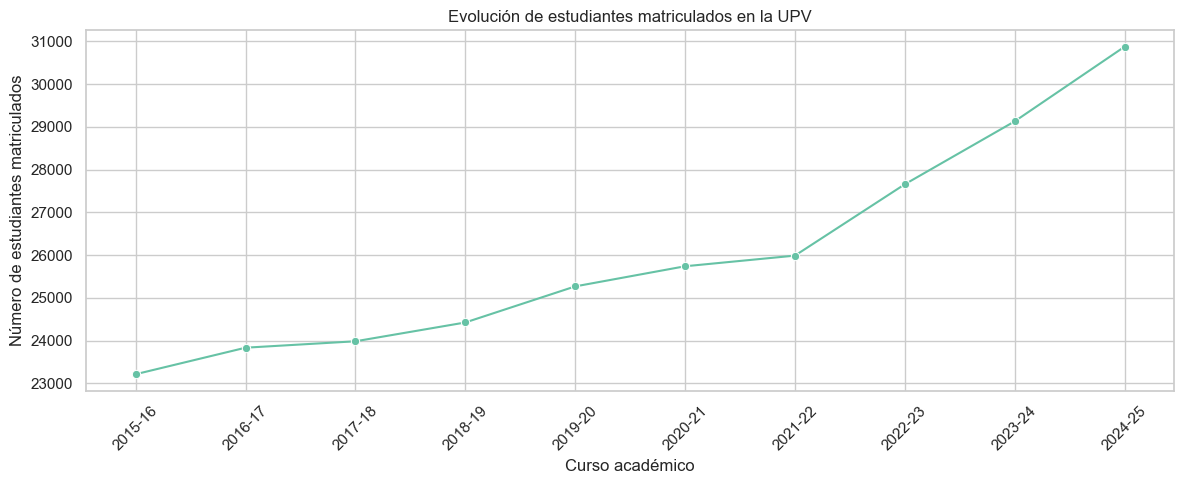

In [17]:

matricula_anual = (
    df_matricula
    .groupby("CURSO", as_index=False)
    .agg(
        ALUMNOS=("NUMERO_ALUMNOS_MATRICULADOS", "sum"),
        TITULACIONES=("COD_RUCT", "nunique"),
        CENTROS=("CENTRO", "nunique")
    )
    .sort_values("CURSO")
)

display(matricula_anual)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=matricula_anual,
    x="CURSO",
    y="ALUMNOS",
    marker="o"
)

plt.title("Evolución de estudiantes matriculados en la UPV")
plt.xlabel("Curso académico")
plt.ylabel("Número de estudiantes matriculados")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


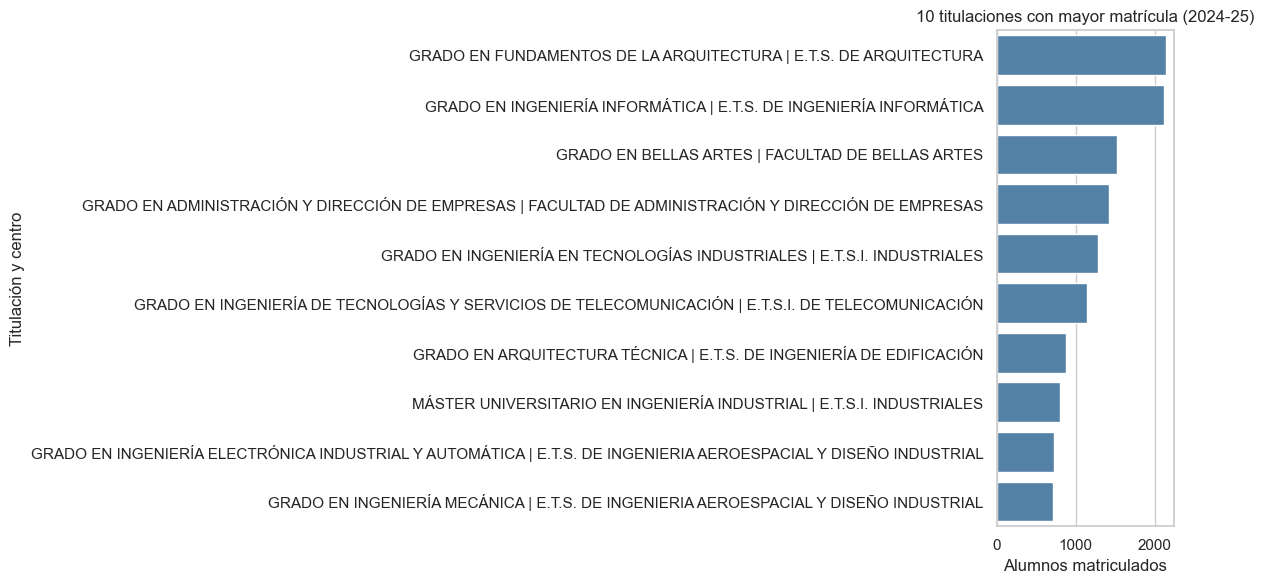

In [18]:

curso_seleccionado = "2024-25"

top_matricula = (
    df_matricula[
        df_matricula["CURSO"] == curso_seleccionado
    ]
    .sort_values(
        "NUMERO_ALUMNOS_MATRICULADOS",
        ascending=False
    )
    .head(10)
    .copy()
)

top_matricula["TITULACION_CENTRO"] = (
    top_matricula["TITULACION"]
    + " | " + top_matricula["CENTRO"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_matricula,
    x="NUMERO_ALUMNOS_MATRICULADOS",
    y="TITULACION_CENTRO",
    color="steelblue"
)

plt.title(f"10 titulaciones con mayor matrícula ({curso_seleccionado})")
plt.xlabel("Alumnos matriculados")
plt.ylabel("Titulación y centro")
plt.tight_layout()
plt.show()


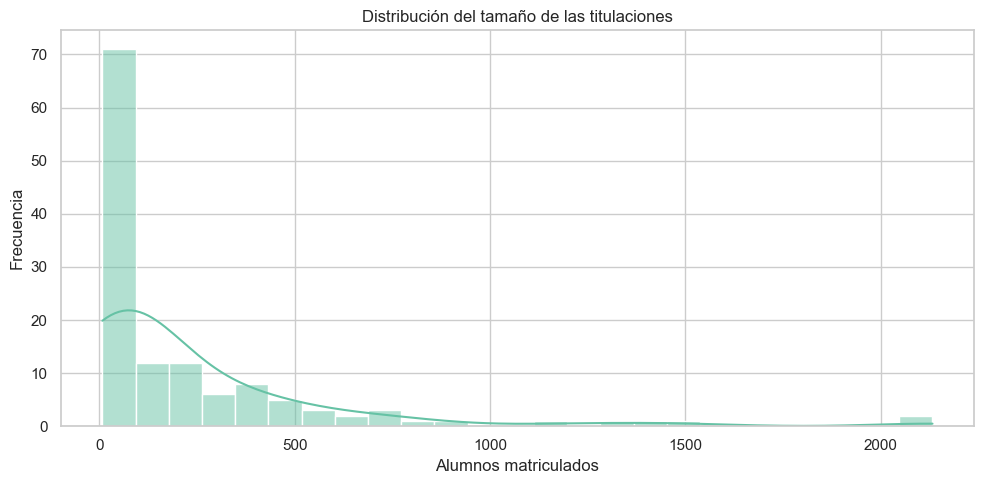

count         130.0
mean     237.507692
std      367.903557
min             8.0
25%           41.25
50%            73.5
75%          304.75
max          2133.0
Name: NUMERO_ALUMNOS_MATRICULADOS, dtype: Float64

In [19]:

matricula_actual = df_matricula[
    df_matricula["CURSO"] == curso_seleccionado
]

plt.figure(figsize=(10, 5))

sns.histplot(
    data=matricula_actual,
    x="NUMERO_ALUMNOS_MATRICULADOS",
    bins=25,
    kde=True
)

plt.title("Distribución del tamaño de las titulaciones")
plt.xlabel("Alumnos matriculados")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

display(
    matricula_actual[
        "NUMERO_ALUMNOS_MATRICULADOS"
    ].describe()
)


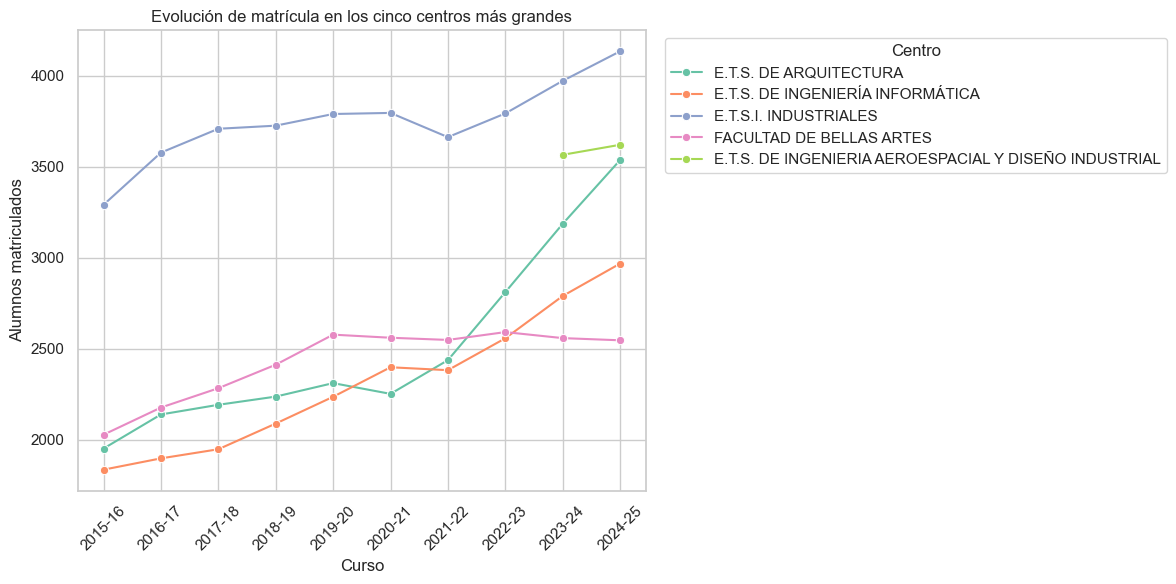

In [20]:

matricula_centros = (
    df_matricula
    .groupby(["CURSO", "CENTRO"], as_index=False)
    ["NUMERO_ALUMNOS_MATRICULADOS"]
    .sum()
)

principales_centros = (
    matricula_actual
    .groupby("CENTRO")["NUMERO_ALUMNOS_MATRICULADOS"]
    .sum()
    .nlargest(5)
    .index
)

df_centros = matricula_centros[
    matricula_centros["CENTRO"].isin(principales_centros)
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_centros,
    x="CURSO",
    y="NUMERO_ALUMNOS_MATRICULADOS",
    hue="CENTRO",
    marker="o"
)

plt.title("Evolución de matrícula en los cinco centros más grandes")
plt.xlabel("Curso")
plt.ylabel("Alumnos matriculados")
plt.xticks(rotation=45)
plt.legend(title="Centro", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


,AÑO,PDI_TOTAL
0,2020,2481
1,2021,2537
2,2022,2566
3,2023,2628
4,2024,2642


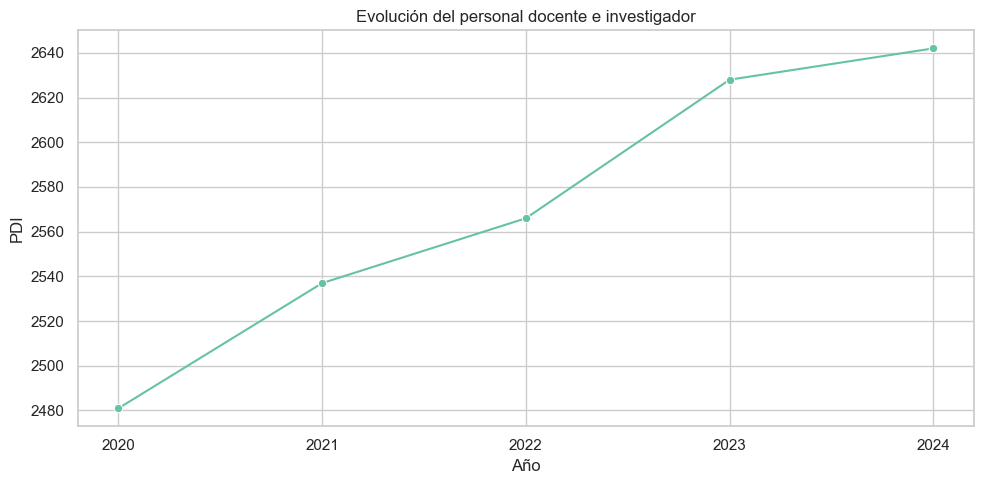

In [21]:

pdi_anual = (
    df_pdi
    .groupby("AÑO", as_index=False)
    .agg(PDI_TOTAL=("CASOS", "sum"))
)

display(pdi_anual)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=pdi_anual,
    x="AÑO",
    y="PDI_TOTAL",
    marker="o"
)

plt.title("Evolución del personal docente e investigador")
plt.xlabel("Año")
plt.ylabel("PDI")
plt.xticks(pdi_anual["AÑO"])
plt.tight_layout()
plt.show()


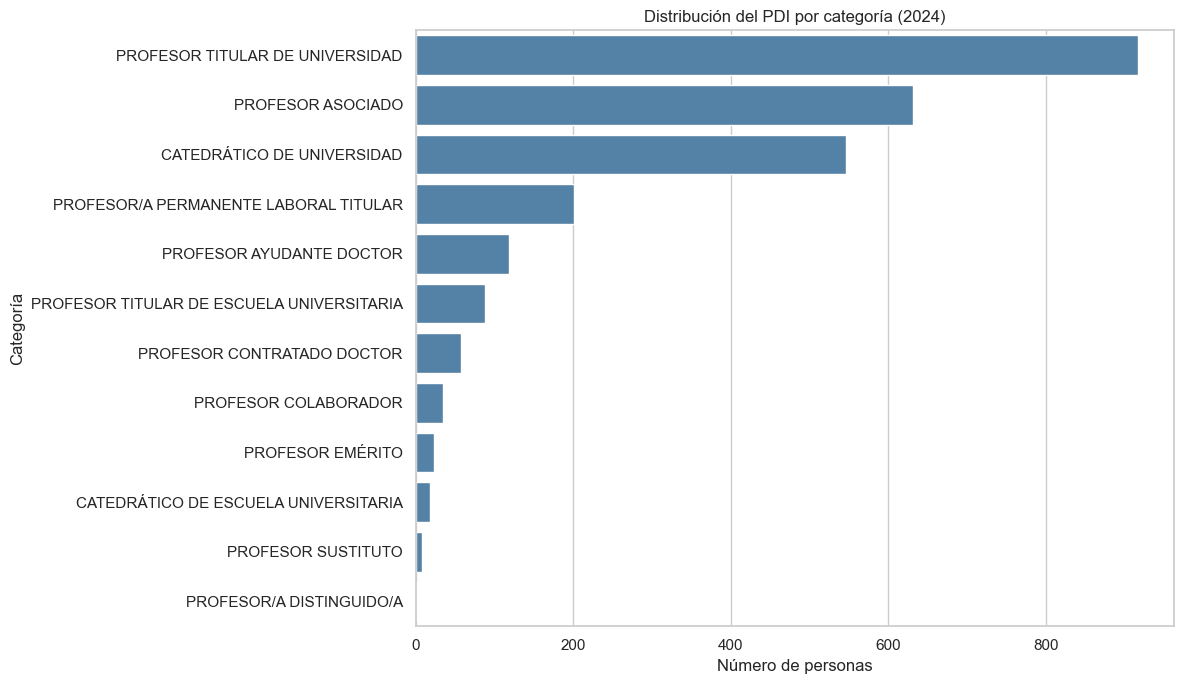

In [22]:

ultimo_año = df_pdi["AÑO"].max()

pdi_categoria = (
    df_pdi[df_pdi["AÑO"] == ultimo_año]
    .groupby("CATEGORÍA", as_index=False)["CASOS"]
    .sum()
    .sort_values("CASOS", ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=pdi_categoria,
    x="CASOS",
    y="CATEGORÍA",
    color="steelblue"
)

plt.title(f"Distribución del PDI por categoría ({ultimo_año})")
plt.xlabel("Número de personas")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()


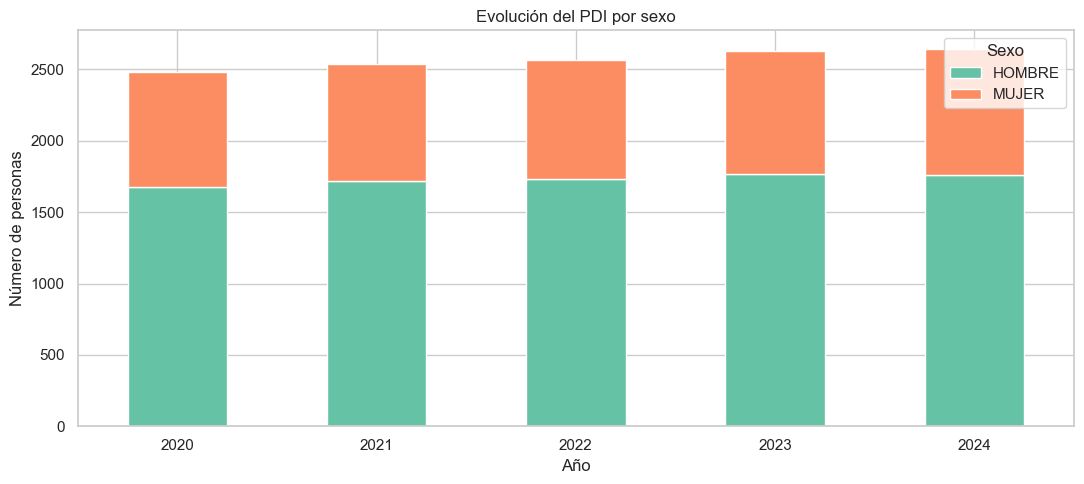

In [23]:

pdi_sexo = (
    df_pdi
    .groupby(["AÑO", "SEXO"], as_index=False)
    ["CASOS"]
    .sum()
)

tabla_pdi_sexo = pdi_sexo.pivot(
    index="AÑO",
    columns="SEXO",
    values="CASOS"
).fillna(0)

tabla_pdi_sexo.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

plt.title("Evolución del PDI por sexo")
plt.xlabel("Año")
plt.ylabel("Número de personas")
plt.legend(title="Sexo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


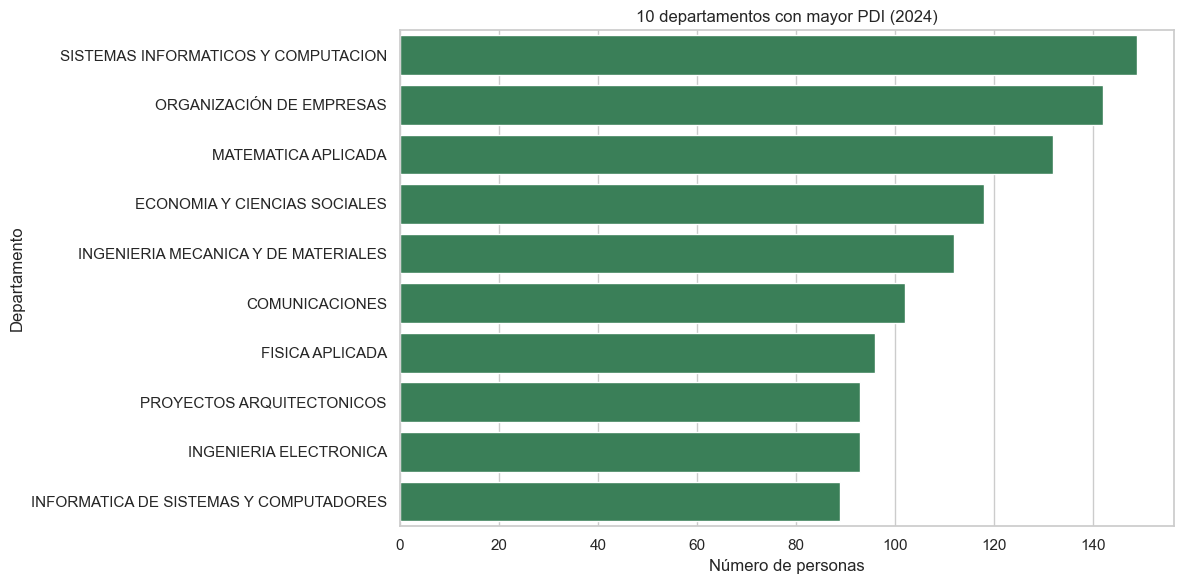

In [24]:

pdi_departamentos = (
    df_pdi[df_pdi["AÑO"] == ultimo_año]
    .groupby("DEPARTAMENTO", as_index=False)["CASOS"]
    .sum()
    .sort_values("CASOS", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=pdi_departamentos,
    x="CASOS",
    y="DEPARTAMENTO",
    color="seagreen"
)

plt.title(f"10 departamentos con mayor PDI ({ultimo_año})")
plt.xlabel("Número de personas")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()


,AÑO,PRESUPUESTO_INICIAL,PRESUPUESTO_DEFINITIVO,GASTO_EJECUTADO
0,2015,299962857.35,339179747.37,298536934.66
1,2016,309291210.3,362710926.04,306446993.4
2,2017,313433494.18,381414552.08,311591452.85
3,2018,317839657.25,394231178.69,317552444.94
4,2019,341303385.38,449390822.39,335315931.04


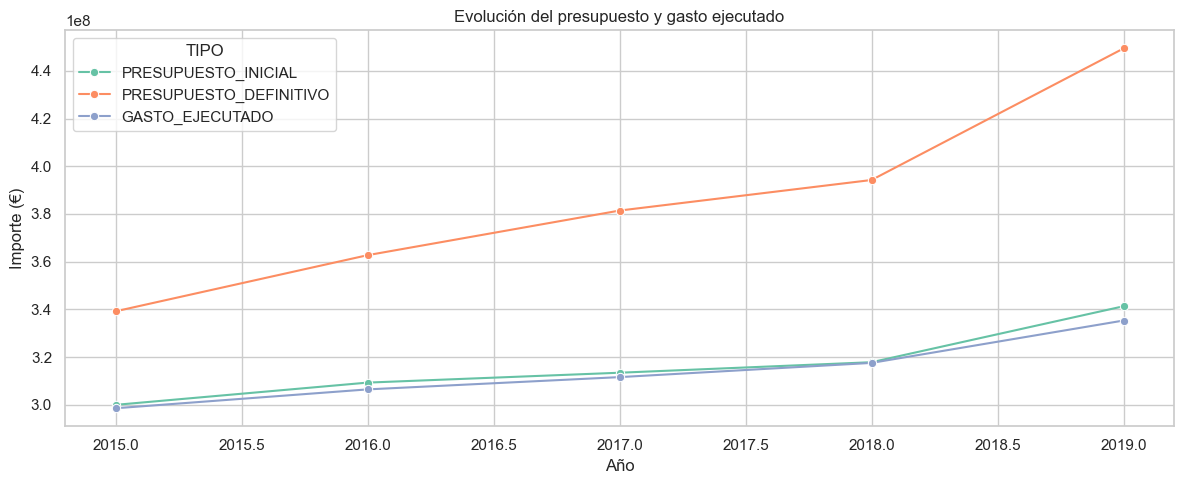

In [25]:

presupuesto_anual = (
    df_presupuesto
    .groupby("AÑO", as_index=False)
    .agg(
        PRESUPUESTO_INICIAL=("PRESUPUESTO_INICIAL_EUR", "sum"),
        PRESUPUESTO_DEFINITIVO=("PRESUPUESTO_DEFINITIVO_EUR", "sum"),
        GASTO_EJECUTADO=("OBLIGACIONES_RECONOCIDAS_NETAS_EUR", "sum")
    )
)

display(presupuesto_anual)

df_presupuesto_grafico = presupuesto_anual.melt(
    id_vars="AÑO",
    value_vars=[
        "PRESUPUESTO_INICIAL",
        "PRESUPUESTO_DEFINITIVO",
        "GASTO_EJECUTADO"
    ],
    var_name="TIPO",
    value_name="EUROS"
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_presupuesto_grafico,
    x="AÑO",
    y="EUROS",
    hue="TIPO",
    marker="o"
)

plt.title("Evolución del presupuesto y gasto ejecutado")
plt.xlabel("Año")
plt.ylabel("Importe (€)")
plt.tight_layout()
plt.show()


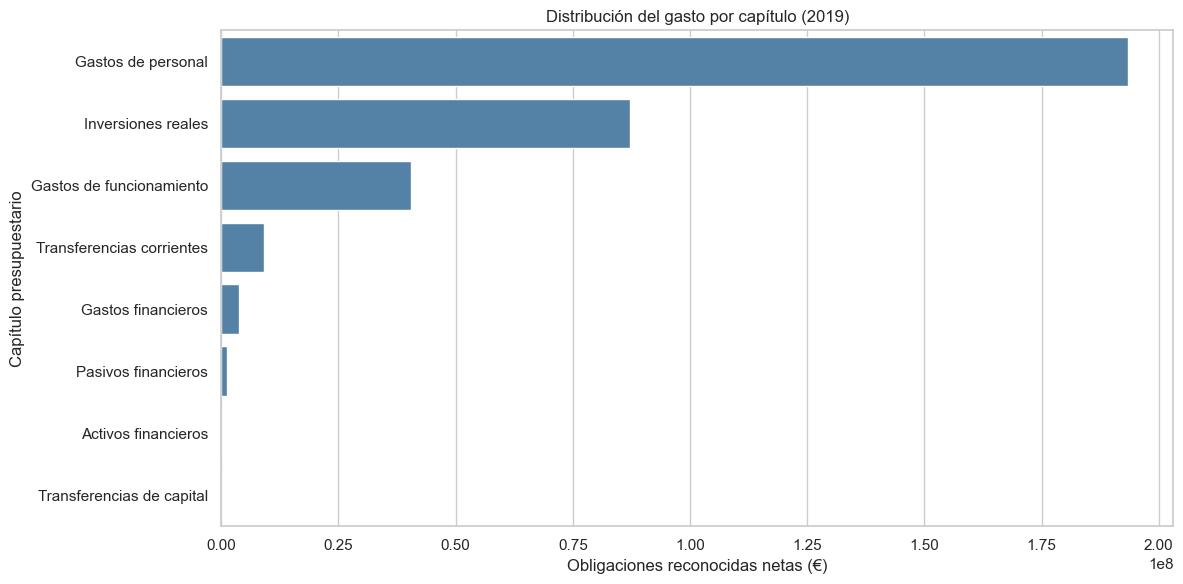

In [26]:

año_presupuesto = df_presupuesto["AÑO"].max()

presupuesto_capitulos = (
    df_presupuesto[
        df_presupuesto["AÑO"] == año_presupuesto
    ]
    .groupby(
        ["CAPITULO", "DESCRIPCION_CAPITULO"],
        as_index=False
    )
    ["OBLIGACIONES_RECONOCIDAS_NETAS_EUR"]
    .sum()
    .sort_values(
        "OBLIGACIONES_RECONOCIDAS_NETAS_EUR",
        ascending=False
    )
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=presupuesto_capitulos,
    x="OBLIGACIONES_RECONOCIDAS_NETAS_EUR",
    y="DESCRIPCION_CAPITULO",
    color="steelblue"
)

plt.title(f"Distribución del gasto por capítulo ({año_presupuesto})")
plt.xlabel("Obligaciones reconocidas netas (€)")
plt.ylabel("Capítulo presupuestario")
plt.tight_layout()
plt.show()


,AÑO,EJECUCION_PCT
0,2015,88.017323
1,2016,84.487941
2,2017,81.693646
3,2018,80.549805
4,2019,74.615661


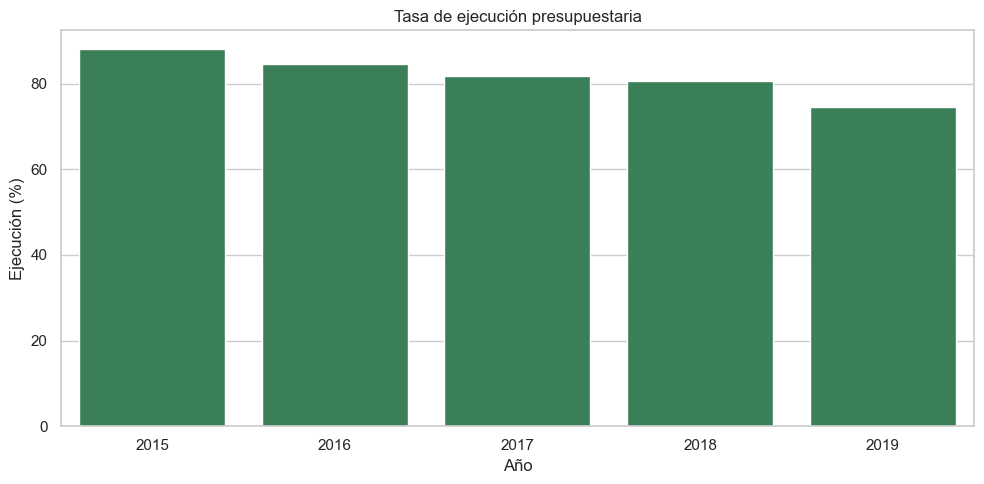

In [27]:

presupuesto_anual["EJECUCION_PCT"] = (
    presupuesto_anual["GASTO_EJECUTADO"]
    / presupuesto_anual["PRESUPUESTO_DEFINITIVO"]
        .replace(0, np.nan)
    * 100
)

display(
    presupuesto_anual[
        ["AÑO", "EJECUCION_PCT"]
    ]
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=presupuesto_anual,
    x="AÑO",
    y="EJECUCION_PCT",
    color="seagreen"
)

plt.title("Tasa de ejecución presupuestaria")
plt.xlabel("Año")
plt.ylabel("Ejecución (%)")
plt.tight_layout()
plt.show()


# GASTO PRESUPUESTARIO POR MATRICULA 

In [28]:

matricula_por_año = (
    df_matricula
    .groupby("AÑO_INICIO", as_index=False)
    .agg(MATRICULAS=("NUMERO_ALUMNOS_MATRICULADOS", "sum"))
)

df_presupuesto_matricula = presupuesto_anual.merge(
    matricula_por_año,
    left_on="AÑO",
    right_on="AÑO_INICIO",
    how="inner",
    validate="one_to_one"
)

df_presupuesto_matricula["GASTO_POR_MATRICULA"] = (
    df_presupuesto_matricula["GASTO_EJECUTADO"]
    / df_presupuesto_matricula["MATRICULAS"].replace(0, np.nan)
)

display(df_presupuesto_matricula)


,AÑO,PRESUPUESTO_INICIAL,PRESUPUESTO_DEFINITIVO,GASTO_EJECUTADO,EJECUCION_PCT,AÑO_INICIO,MATRICULAS,GASTO_POR_MATRICULA
0,2015,299962857.35,339179747.37,298536934.66,88.017323,2015,23215,12859.656888
1,2016,309291210.3,362710926.04,306446993.4,84.487941,2016,23835,12857.016715
2,2017,313433494.18,381414552.08,311591452.85,81.693646,2017,23985,12991.096637
3,2018,317839657.25,394231178.69,317552444.94,80.549805,2018,24425,13001.123641
4,2019,341303385.38,449390822.39,335315931.04,74.615661,2019,25269,13269.853617


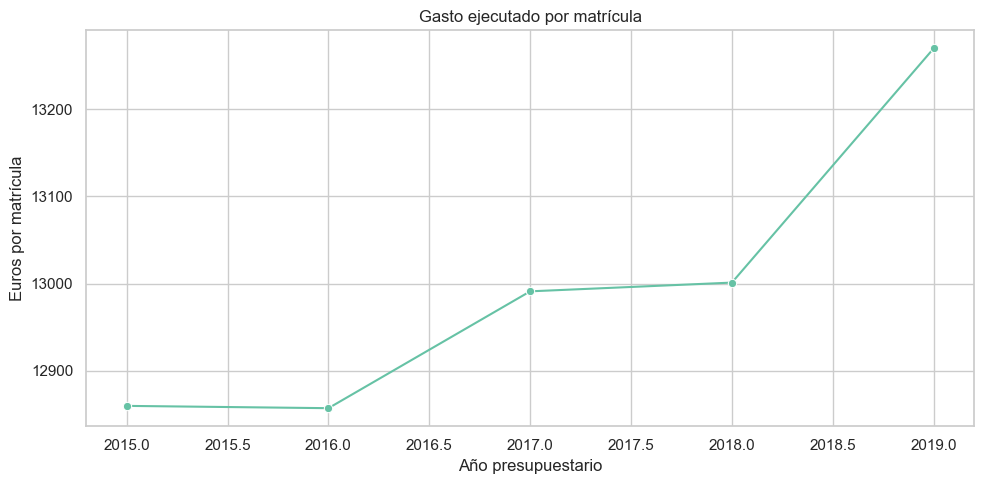

In [29]:

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df_presupuesto_matricula,
    x="AÑO",
    y="GASTO_POR_MATRICULA",
    marker="o"
)

plt.title("Gasto ejecutado por matrícula")
plt.xlabel("Año presupuestario")
plt.ylabel("Euros por matrícula")
plt.tight_layout()
plt.show()


In [30]:

df_pdi_matricula = pdi_anual.merge(
    matricula_por_año,
    left_on="AÑO",
    right_on="AÑO_INICIO",
    how="inner",
    validate="one_to_one"
)

df_pdi_matricula["MATRICULAS_POR_PDI"] = (
    df_pdi_matricula["MATRICULAS"]
    / df_pdi_matricula["PDI_TOTAL"].replace(0, np.nan)
)

display(df_pdi_matricula)


,AÑO,PDI_TOTAL,AÑO_INICIO,MATRICULAS,MATRICULAS_POR_PDI
0,2020,2481,2020,25740,10.374849
1,2021,2537,2021,25989,10.243989
2,2022,2566,2022,27658,10.778644
3,2023,2628,2023,29130,11.084475
4,2024,2642,2024,30876,11.686601


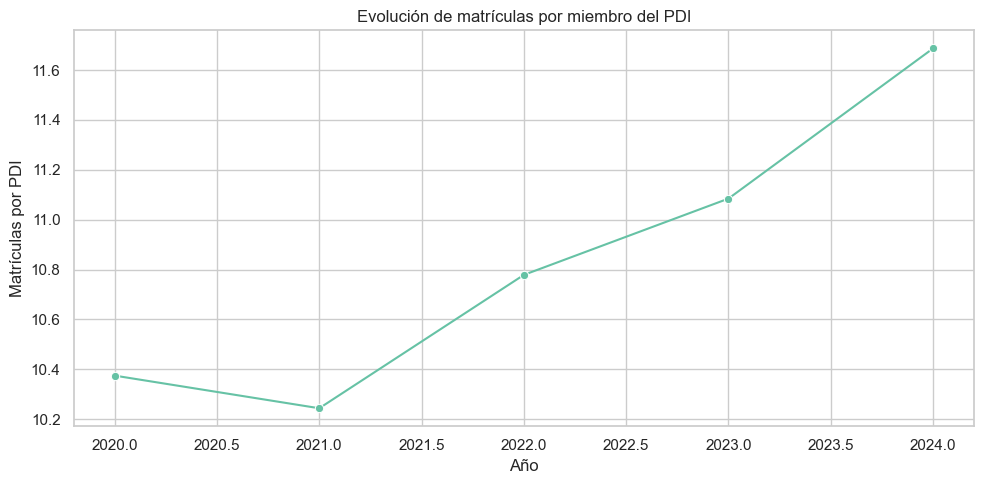

In [31]:

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df_pdi_matricula,
    x="AÑO",
    y="MATRICULAS_POR_PDI",
    marker="o"
)

plt.title("Evolución de matrículas por miembro del PDI")
plt.xlabel("Año")
plt.ylabel("Matrículas por PDI")
plt.tight_layout()
plt.show()


In [32]:

from pathlib import Path

# Ruta desde la carpeta notebooks/
output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

# Datasets preparados
datasets_salida = {
    "upv_matricula.csv": df_matricula,
    "upv_pdi.csv": df_pdi,
    "upv_presupuesto.csv": df_presupuesto,
    
    # Datos agregados para el dashboard
    "upv_matricula_anual.csv": matricula_anual,
    "upv_pdi_anual.csv": pdi_anual,
    "upv_presupuesto_anual.csv": presupuesto_anual,

    # Indicadores normalizados
    "upv_presupuesto_matricula.csv": df_presupuesto_matricula,
    "upv_pdi_matricula.csv": df_pdi_matricula
}

for nombre, df in datasets_salida.items():
    ruta = output_path / nombre

    df.to_csv(
        ruta,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Guardado: {nombre} ({len(df)} filas)")


Guardado: upv_matricula.csv (1173 filas)
Guardado: upv_pdi.csv (2257 filas)
Guardado: upv_presupuesto.csv (290 filas)
Guardado: upv_matricula_anual.csv (10 filas)
Guardado: upv_pdi_anual.csv (5 filas)
Guardado: upv_presupuesto_anual.csv (5 filas)
Guardado: upv_presupuesto_matricula.csv (5 filas)
Guardado: upv_pdi_matricula.csv (5 filas)
